# 04. Exploratory Data Analysis (Training Set Only)

**Project:** Explainable ML for screening kidney abnormality markers among US adults with diabetes (NHANES 2017–March 2020 pre-pandemic)

## Objective
Describe the distributions, missingness, outliers, and outcome patterns of candidate predictors in order to justify preprocessing and feature-selection decisions.

## Data and scope

- **Input:** `data/processed/train.csv` (n = 1,204; 80% stratified split, random_state=42).
- **Outcome:** `kidney_marker` = 1 if eGFR < 60 mL/min/1.73 m² OR UACR ≥ 30 mg/g; 0 if both are measured and normal.
- **Design:** Cross-sectional. Findings represent associations at a single time point, not causation or future risk.
- **Leakage safeguard:** The test set (n = 302) is not opened in this notebook.
- **Not survey-weighted:** Statistics are unweighted sample statistics and do not estimate US population prevalence.

In [20]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("../data/processed/train.csv")

print("Training dataset shape:", train.shape)
print("\nKidney marker distribution:")
print(train["kidney_marker"].value_counts())

Training dataset shape: (1204, 35)

Kidney marker distribution:
kidney_marker
0.0    684
1.0    520
Name: count, dtype: int64


## 1. Descriptive statistics and skewness

**Purpose:** Summarise each continuous candidate predictor (count, mean, SD, range) and quantify skewness to decide whether transformation is needed.

**Method:** `describe()` and sample skewness. As a rule of thumb, |skew| > 1 indicates a pronounced tail.

**Variables:** age (`RIDAGEYR`), family income-to-poverty ratio (`INDFMPIR`), HbA1c (`LBXGH`), BMI (`BMXBMI`), waist circumference (`BMXWAIST`), systolic and diastolic blood pressure (`BPXOSY1`, `BPXODI1`).

In [21]:
# Continuous candidate predictors
num = [
    "RIDAGEYR",
    "INDFMPIR",
    "LBXGH",
    "BMXBMI",
    "BMXWAIST",
    "BPXOSY1",
    "BPXODI1"
]

# Descriptive statistics
print("Descriptive statistics:")
print(train[num].describe().round(2).T)

# Skewness
print("\nSkewness:")
print(train[num].skew().round(2))

Descriptive statistics:
           count    mean    std   min     25%     50%     75%    max
RIDAGEYR  1204.0   61.95  12.71  20.0   54.00   63.00   71.00   80.0
INDFMPIR  1041.0    2.48   1.58   0.0    1.15    1.96    3.94    5.0
LBXGH     1187.0    7.45   1.64   4.1    6.50    6.90    8.10   16.2
BMXBMI    1178.0   32.88   7.83  15.4   27.60   31.55   36.50   84.4
BMXWAIST  1129.0  110.23  15.97  67.4   99.00  109.10  120.10  170.8
BPXOSY1   1078.0  131.70  21.18  66.0  117.00  129.00  144.00  224.0
BPXODI1   1078.0   75.26  12.19  36.0   67.00   75.00   83.00  137.0

Skewness:
RIDAGEYR   -0.54
INDFMPIR    0.43
LBXGH       1.60
BMXBMI      1.39
BMXWAIST    0.41
BPXOSY1     0.68
BPXODI1     0.22
dtype: float64


## 2. Distributions by outcome status

**Purpose:** Visually compare each predictor's distribution between participants with and without a kidney marker, and screen for implausible values and coding artefacts.

**Method:** Overlaid histograms (30 bins) by `kidney_marker`. Missing values are omitted from each panel.

**What to look for:** distribution shift between groups, pile-ups at a single value (top-coding), and impossible values.

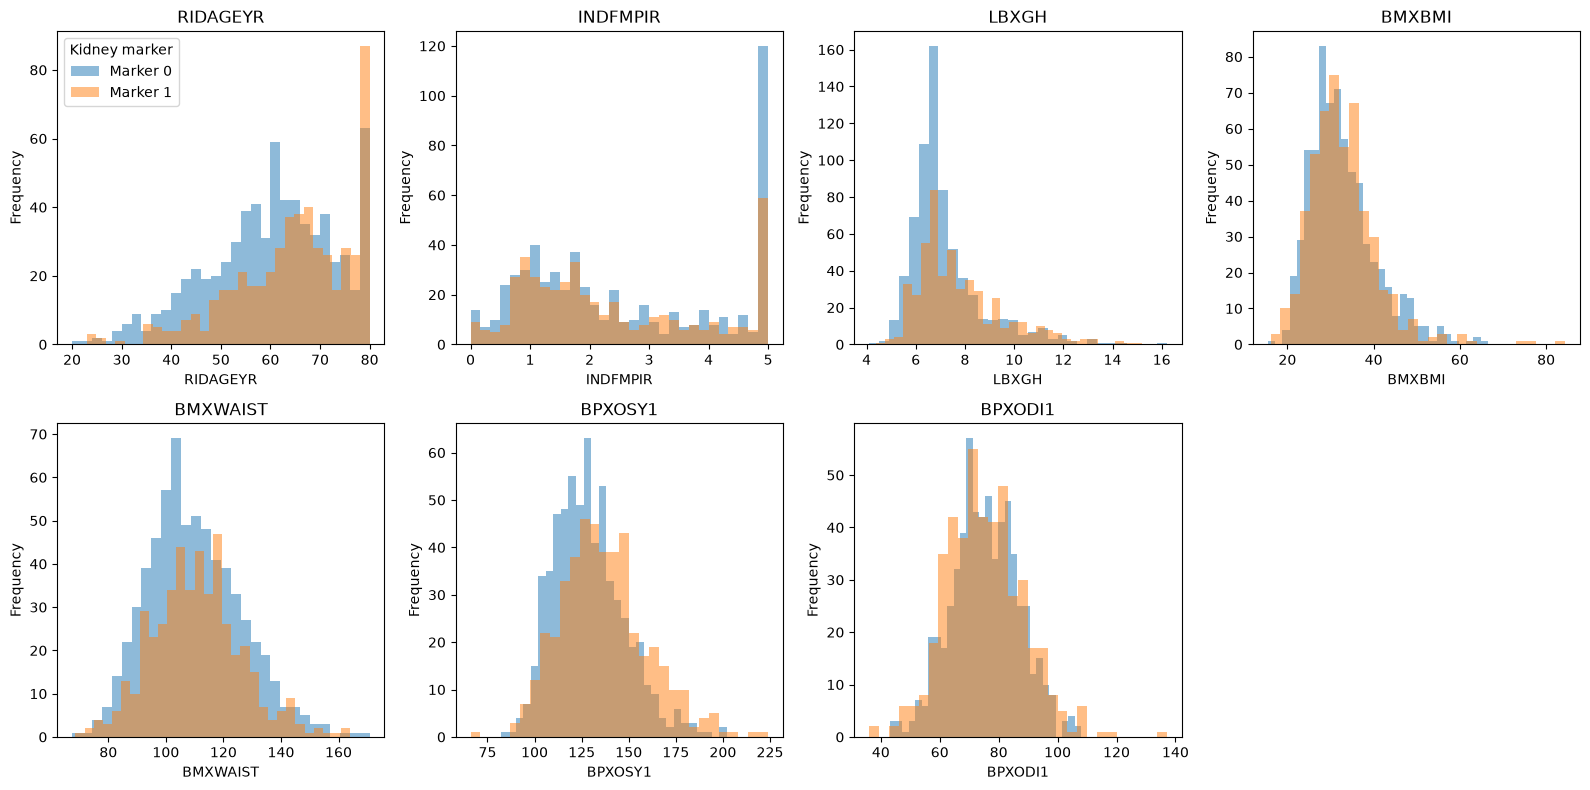

In [22]:
# Histograms of numerical predictors by kidney marker
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.ravel(), num):
    for label, group in train.groupby("kidney_marker"):
        ax.hist(
            group[col].dropna(),
            bins=30,
            alpha=0.5,
            label=f"Marker {int(label)}"
        )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

axes.ravel()[0].legend(title="Kidney marker")

# Hide the unused eighth subplot
axes.ravel()[-1].set_visible(False)

plt.tight_layout()
plt.savefig(
    "../reports/figures/eda_numeric_by_outcome.png",
    dpi=150
)
plt.show()

## 3. Outcome rate across clinically defined groups and collinearity

**Purpose:** (a) Describe how the proportion with a kidney marker varies across clinically meaningful strata. (b) Quantify linear correlation among continuous predictors to identify redundancy before modelling.

**Method:**
- Age bands: 20–44, 45–59, 60–69, 70+.
- HbA1c bands: < 6.5, 6.5–8, 8–10, > 10 %.
- Outcome rate (mean of the binary label) and group size for each stratum.
- Pearson correlation matrix of continuous predictors.

**Caution:** Strata are descriptive. Small groups (e.g. "unknown" smoking, n = 2) are not interpretable.

In [23]:
# 1. Age groups
train["age_group"] = pd.cut(
    train["RIDAGEYR"],
    bins=[19, 44, 59, 69, 80],
    labels=["20-44", "45-59", "60-69", "70+"]
)

# 2. HbA1c groups
train["a1c_group"] = pd.cut(
    train["LBXGH"],
    bins=[0, 6.5, 8, 10, 20],
    labels=["<6.5", "6.5-8", "8-10", ">10"]
)

# 3. Outcome rate across groups
for group in [
    "age_group",
    "a1c_group",
    "smoking",
    "insulin",
    "female"
]:
    print(f"\nOutcome rate by {group}:")
    print(
        train.groupby(group, observed=True)["kidney_marker"]
        .agg(["mean", "count"])
        .round(2)
    )

# 4. Correlation among numerical predictors
print("\nCorrelation matrix:")
print(train[num].corr().round(2))


Outcome rate by age_group:
           mean  count
age_group             
20-44      0.28    127
45-59      0.34    325
60-69      0.46    390
70+        0.54    362

Outcome rate by a1c_group:
           mean  count
a1c_group             
<6.5       0.35    354
6.5-8      0.39    535
8-10       0.55    196
>10        0.61    102

Outcome rate by smoking:
         mean  count
smoking             
current  0.43    185
former   0.49    379
never    0.39    638
unknown  0.50      2

Outcome rate by insulin:
         mean  count
insulin             
0.0      0.39    698
1.0      0.66    289

Outcome rate by female:
        mean  count
female             
0       0.47    642
1       0.39    562

Correlation matrix:
          RIDAGEYR  INDFMPIR  LBXGH  BMXBMI  BMXWAIST  BPXOSY1  BPXODI1
RIDAGEYR      1.00      0.04  -0.17   -0.21     -0.10     0.25    -0.29
INDFMPIR      0.04      1.00  -0.11   -0.05     -0.04    -0.07     0.02
LBXGH        -0.17     -0.11   1.00   -0.02     -0.01    -0.02  

## 4. ## Findings and interpretation

### Data quality

- Training data contains 1,204 participants.
- Age is top-coded at 80 years, and the income-to-poverty ratio is top-coded at 5.0. These are NHANES measurement conventions, not automatically outliers.
- Maximum HbA1c is 16.2%, BMI is 84.4 kg/m², and systolic BP is 224 mmHg. Extreme observations are retained pending clinical plausibility assessment.

### Distributions

- HbA1c (skew = 1.60) and BMI (skew = 1.39) are right-skewed.
- Age is slightly left-skewed (−0.54).
- Income-to-poverty ratio, waist circumference, and blood pressure show relatively mild skewness.
- The histograms show substantial overlap between kidney-marker groups for several predictors, although age, HbA1c, and systolic BP show some distributional differences.

### Associations with the outcome (unadjusted)

- **Age:** Kidney-marker rate increases across age groups (28%, 34%, 46%, and 54%). Age also contributes directly to the eGFR calculation.
- **HbA1c:** Kidney-marker rates increase across HbA1c groups (35%, 39%, 55%, and 61%). The lowest HbA1c group includes participants who entered the cohort through self-reported diabetes despite HbA1c below 6.5%.
- **Blood pressure:** Histograms suggest somewhat higher systolic BP among participants with kidney markers. Diastolic BP distributions overlap substantially.
- **Insulin:** The kidney-marker rate is 66% among insulin users and 39% among non-users. This is an unadjusted association and may reflect disease severity, treatment selection, or reverse causation.
- **Smoking:** Former smokers show the highest kidney-marker rate (49%), followed by current smokers (43%) and never smokers (39%). Age and other confounding factors may contribute.
- **Sex:** The unadjusted kidney-marker rate is 47% among males and 39% among females.

### Collinearity

- BMI and waist circumference are strongly correlated (r = 0.89), indicating substantial redundancy.
- Systolic and diastolic blood pressure are moderately correlated (r = 0.52).
- Other continuous predictor pairs show relatively weak correlations.

### Decisions taken from this EDA

| Decision | Rationale |
|---|---|
| Median imputation and missingness indicators, fitted within training folds only | Several predictors contain missing observations |
| Standard scaling for logistic regression | Enables predictors to be compared on similar scales |
| Exclude waist circumference from the primary model; retain for sensitivity analysis | Strong correlation with BMI (r = 0.89) |
| Derive smoking status using questionnaire skip patterns | Follow-up smoking responses are structurally missing for never-smokers |
| Preserve missing insulin responses | Missing/not-asked responses must not be classified as non-use |
| Run sensitivity models without HbA1c and without insulin | HbA1c contributes to cohort selection; insulin may introduce treatment-related bias |

### Limitations

This EDA is unweighted and descriptive. The group comparisons are unadjusted and do not establish statistical significance or causation. The analysis uses a cross-sectional sample of 1,204 training participants. The findings should not be interpreted as US population prevalence or clinical CKD diagnoses.

In [24]:
import sys
sys.path.append("..")
import pandas as pd
from src.data_processing import load_raw_tables

tables = load_raw_tables("../data/raw")

In [25]:
keep = {
 "P_DEMO": ["SEQN", "RIDSTATR", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "RIDEXPRG",
           "INDFMPIR", "WTMECPRP", "SDMVPSU", "SDMVSTRA"],
"P_DIQ":["SEQN","DIQ010","DIQ050","DIQ070","DIQ160"],
 "P_GHB":["SEQN","LBXGH"],
 "P_BIOPRO":["SEQN","LBXSCR"],
 "P_ALB_CR":["SEQN","URXUMA","URXUCR","URDACT"],
 "P_BMX":["SEQN","BMXBMI","BMXWAIST"],
 "P_BPXO":["SEQN","BPXOSY1","BPXODI1"],
 "P_SMQ":["SEQN","SMQ020","SMQ040"]
}
merged = tables["P_DEMO"][keep["P_DEMO"]].copy()
for name in list(keep)[1:]:
    merged = merged.merge(tables[name][keep[name]], on="SEQN",
                          how="left", validate="one_to_one")
print(merged.shape)
assert len(merged) == 15560

(15560, 25)


In [26]:
# Identify adults aged 20 years or older
adults = merged[merged.RIDAGEYR >= 20].copy()

# Diabetes identification criteria
adults["dm_self"] = adults["DIQ010"] == 1
adults["dm_a1c"] = adults["LBXGH"] >= 6.5

# Primary diabetes definition:
# Self-reported diabetes OR HbA1c >= 6.5%
adults["diabetes"] = adults["dm_self"] | adults["dm_a1c"]

# Flag oral medication users reporting prediabetes
# without a diabetes diagnosis
adults["oral_med_prediabetes_only"] = (
    (adults["DIQ010"] == 2) &
    (adults["DIQ160"] == 1) &
    (adults["DIQ070"] == 1)
)

# Summary counts
print("Adults:", len(adults))
print("Self-reported diabetes:", adults["dm_self"].sum())
print("HbA1c >= 6.5%:", adults["dm_a1c"].sum())
print("Combined diabetes cohort:", adults["diabetes"].sum())

# Participants meeting each criterion
only_self = (
    adults["dm_self"] & ~adults["dm_a1c"]
).sum()

only_a1c = (
    adults["dm_a1c"] & ~adults["dm_self"]
).sum()

both = (
    adults["dm_self"] & adults["dm_a1c"]
).sum()

print("Only self-reported:", only_self)
print("Only HbA1c:", only_a1c)
print("Both criteria:", both)

# Medication-related descriptive information
pills_no_dx = adults[
    (adults["DIQ070"] == 1) &
    (adults["DIQ010"] != 1)
]

print(
    "Pills without diabetes diagnosis:", len(pills_no_dx),
    "| HbA1c >= 6.5%:", pills_no_dx["dm_a1c"].sum()
)

print(
    "Oral medication users reporting prediabetes "
    "without diabetes diagnosis:",
    adults["oral_med_prediabetes_only"].sum()
)

Adults: 9232
Self-reported diabetes: 1420
HbA1c >= 6.5%: 1171
Combined diabetes cohort: 1704
Only self-reported: 533
Only HbA1c: 284
Both criteria: 887
Pills without diabetes diagnosis: 108 | HbA1c >= 6.5%: 47
Oral medication users reporting prediabetes without diabetes diagnosis: 52


In [27]:
print(pd.crosstab(adults.DIQ010, adults.DIQ070, dropna=False))

DIQ070   1.0  2.0  9.0   NaN
DIQ010                      
1.0     1016  401    3     0
2.0       52  859    1  6633
3.0       56  205    1     0
9.0        0    2    0     3


In [28]:
# Diabetes cohort among adults
dm = adults[adults.diabetes].copy()

print("Diabetes cohort:", len(dm))

# Pregnancy status
print("\nPregnancy codes:")
print(dm.RIDEXPRG.value_counts(dropna=False))

# Adults without self-reported diabetes and with missing HbA1c
unknown_status = (
    (~adults.dm_self) &
    adults.LBXGH.isna()
)

print(
    "\nUnknown status (no self-reported diabetes, HbA1c missing):",
    unknown_status.sum()
)

# Missing HbA1c and examination weight
print("\nCohort HbA1c missing:", dm.LBXGH.isna().sum())

print(
    "Cohort WTMECPRP missing:",
    dm.WTMECPRP.isna().sum(),
    "| equal to 0:",
    (dm.WTMECPRP == 0).sum()
)

Diabetes cohort: 1704

Pregnancy codes:
RIDEXPRG
NaN    1607
2.0      84
3.0      10
1.0       3
Name: count, dtype: int64

Unknown status (no self-reported diabetes, HbA1c missing): 991

Cohort HbA1c missing: 160
Cohort WTMECPRP missing: 0 | equal to 0: 96


In [29]:
# Check whether RIDSTATR=2 matches WTMECPRP > 0
print(pd.crosstab(
    adults.RIDSTATR,
    adults.WTMECPRP > 0,
    dropna=False
))

# Restrict to examined adults
mec = adults[adults.RIDSTATR == 2].copy()

# Identify the updated diabetes cohort
dm_mec = mec[mec.diabetes].copy()

print("\nExamined adults:", len(mec))
print("Diabetes cohort:", len(dm_mec))

# Check missing HbA1c
print("Cohort HbA1c missing:", dm_mec.LBXGH.isna().sum())

# Check unknown diabetes status
unknown_status = (
    ~mec.dm_self &
    mec.LBXGH.isna()
)

print("Unknown status:", unknown_status.sum())

# Check pregnancy status
print("\nPregnancy status:")
print(dm_mec.RIDEXPRG.value_counts(dropna=False))

WTMECPRP  False  True 
RIDSTATR              
1.0         688      0
2.0           0   8544

Examined adults: 8544
Diabetes cohort: 1608
Cohort HbA1c missing: 64
Unknown status: 399

Pregnancy status:
RIDEXPRG
NaN    1517
2.0      84
3.0       4
1.0       3
Name: count, dtype: int64


cohort attrition table and outcome availability

In [30]:
# Final cohort: examined adults with diabetes,
# excluding pregnant and pregnancy-status-unascertained participants

cohort = dm_mec[
    ~dm_mec.RIDEXPRG.isin([1, 3])
].copy()

print("Final cohort:", len(cohort))

# Cohort attrition
flow = pd.DataFrame({
    "step": [
        "All participants",
        "Adults >=20",
        "Examined adults",
        "Diabetes (self-reported OR HbA1c >= 6.5%)",
        "Excluding pregnant/unascertained"
    ],
    "n": [
        len(merged),
        len(adults),
        len(mec),
        len(dm_mec),
        len(cohort)
    ]
})

display(flow)

# Kidney outcome availability
print("Creatinine missing:", cohort.LBXSCR.isna().sum())
print("UACR missing:", cohort.URDACT.isna().sum())
print(
    "Both missing:",
    (cohort.LBXSCR.isna() & cohort.URDACT.isna()).sum()
)
print("UACR >= 30:", (cohort.URDACT >= 30).sum())

Final cohort: 1601


,step,n
0,All participants,15560
1,Adults >=20,9232
2,Examined adults,8544
3,Diabetes (self-reported OR HbA1c >= 6.5%),1608
4,Excluding pregnant/unascertained,1601


Creatinine missing: 114
UACR missing: 56
Both missing: 15
UACR >= 30: 519


In [31]:
import numpy as np
from src.outcome_definition import egfr_ckdepi_2021, label_outcome

# Calculate kidney outcome using the updated cohort
labeled = label_outcome(cohort)

# Check kidney marker distribution
print("Kidney marker distribution:")
print(labeled.kidney_marker.value_counts(dropna=False))

# eGFR summary
print("\neGFR summary:")
print(labeled.egfr.describe())

# Kidney abnormality counts
print("\neGFR < 60:", (labeled.egfr < 60).sum())
print("UACR >= 30:", (labeled.URDACT >= 30).sum())

Kidney marker distribution:
kidney_marker
0.0    855
1.0    651
NaN     95
Name: count, dtype: int64

eGFR summary:
count    1487.000000
mean       83.507385
std        25.319714
min         2.958234
25%        67.338418
50%        87.786610
75%       102.486037
max       145.145698
Name: egfr, dtype: float64

eGFR < 60: 271
UACR >= 30: 519


In [32]:
from src.outcome_definition import egfr_ckdepi_2021, label_outcome

print(egfr_ckdepi_2021(np.array([1.0]), np.array([50]), np.array([False])))
print(egfr_ckdepi_2021(np.array([1.0]), np.array([50]), np.array([True])))

labeled = label_outcome(cohort)
print(labeled.kidney_marker.value_counts(dropna=False))
print(labeled.egfr.describe())
print("eGFR < 60:", (labeled.egfr < 60).sum())

[91.69147861]
[68.63349666]
kidney_marker
0.0    855
1.0    651
NaN     95
Name: count, dtype: int64
count    1487.000000
mean       83.507385
std        25.319714
min         2.958234
25%        67.338418
50%        87.786610
75%       102.486037
max       145.145698
Name: egfr, dtype: float64
eGFR < 60: 271


In [33]:
# Retain participants with an available kidney outcome
model_df = labeled[
    labeled.kidney_marker.notna()
].copy()

print("Modelling dataset shape:", model_df.shape)
print("\nKidney marker distribution:")
print(model_df.kidney_marker.value_counts())

# Sensitivity-analysis flag
model_df["pills_no_dx"] = (
    (model_df.DIQ070 == 1) &
    (model_df.DIQ010 != 1)
)

print(
    "\nPills without diabetes diagnosis:",
    model_df.pills_no_dx.sum()
)

# Save updated dataset
model_df.to_csv(
    "../data/interim/cohort_labeled.csv",
    index=False
)

Modelling dataset shape: (1506, 31)

Kidney marker distribution:
kidney_marker
0.0    855
1.0    651
Name: count, dtype: int64

Pills without diabetes diagnosis: 45


In [34]:
# Lowest eGFR rows: are they real?
print(labeled.sort_values("egfr")[["RIDAGEYR","RIAGENDR","LBXSCR","egfr","URDACT"]].head(8))
print("Max creatinine:", labeled.LBXSCR.max())

# Reasons for NaN labels
nan = labeled[labeled.kidney_marker.isna()]
print("Unlabeled:", len(nan))
print("Both missing:", (nan.egfr.isna() & nan.URDACT.isna()).sum())
print("Only creatinine missing (UACR normal):", (nan.egfr.isna() & nan.URDACT.notna()).sum())
print("Only UACR missing (eGFR normal):", (nan.egfr.notna() & nan.URDACT.isna()).sum())

       RIDAGEYR  RIAGENDR  LBXSCR      egfr   URDACT
11393      80.0       1.0   14.97  2.958234  1172.26
5749       72.0       2.0   10.96  3.383306      NaN
742        45.0       2.0   10.60  4.165567  3903.57
9136       66.0       1.0   10.78  4.785974  1555.26
15454      51.0       2.0    7.97  5.650477      NaN
13729      45.0       1.0    8.36  7.399229  5897.81
1359       66.0       1.0    7.43  7.480425      NaN
4568       80.0       1.0    6.75  7.693682  1561.18
Max creatinine: 14.97
Unlabeled: 95
Both missing: 15
Only creatinine missing (UACR normal): 63
Only UACR missing (eGFR normal): 17


In [35]:
# Keep only labelable people for modeling; keep the full labeled table for the report
model_df = labeled[labeled.kidney_marker.notna()].copy()
print(model_df.shape, model_df.kidney_marker.value_counts())

# Flag the sensitivity-analysis group: pills without a diabetes diagnosis
model_df["pills_no_dx"] = (model_df.DIQ070 == 1) & (model_df.DIQ010 != 1)
print("Pills-no-dx in modeling sample:", model_df.pills_no_dx.sum())

model_df.to_csv("../data/interim/cohort_labeled.csv", index=False)

(1506, 31) kidney_marker
0.0    855
1.0    651
Name: count, dtype: int64
Pills-no-dx in modeling sample: 45


In [36]:
pregnancy_check = adults[
    (adults.RIAGENDR == 2) &
    (adults.RIDAGEYR.between(20, 44))
]

print("Women aged 20–44:", len(pregnancy_check))

print("\nPregnancy status:")
print(pregnancy_check["RIDEXPRG"].value_counts(dropna=False))

print("\nMissing pregnancy status:")
print(pregnancy_check["RIDEXPRG"].isna().sum())

Women aged 20–44: 1874

Pregnancy status:
RIDEXPRG
2.0    1604
3.0     183
1.0      87
Name: count, dtype: int64

Missing pregnancy status:
0


In [37]:
pregnancy_check = adults[
    (adults.RIAGENDR == 2) &
    (adults.RIDAGEYR.between(20, 44))
]

print("Women aged 20–44:", len(pregnancy_check))

print("\nPregnancy status:")
print(pregnancy_check["RIDEXPRG"].value_counts(dropna=False))

print("\nMissing pregnancy status:")
print(pregnancy_check["RIDEXPRG"].isna().sum())

Women aged 20–44: 1874

Pregnancy status:
RIDEXPRG
2.0    1604
3.0     183
1.0      87
Name: count, dtype: int64

Missing pregnancy status:
0


In [38]:
print("Diabetes diagnosis vs prediabetes:")
print(pd.crosstab(
    adults["DIQ010"],
    adults["DIQ160"],
    dropna=False
))

print("\nOral medication users without diagnosed diabetes:")
print(
    adults.loc[
        (adults["DIQ010"] == 2) &
        (adults["DIQ070"] == 1),
        "DIQ160"
    ].value_counts(dropna=False)
)

Diabetes diagnosis vs prediabetes:
DIQ160  1.0   2.0  9.0   NaN
DIQ010                      
1.0       0     0    0  1420
2.0     912  6621   12     0
3.0       0     0    0   262
9.0       2     2    1     0

Oral medication users without diagnosed diabetes:
DIQ160
1.0    52
Name: count, dtype: int64


In [39]:
check = pd.read_csv("../data/interim/cohort_labeled.csv")

print("Saved dataset shape:", check.shape)
print("Missing target values:", check.kidney_marker.isna().sum())
print("Duplicate participant IDs:", check.SEQN.duplicated().sum())

Saved dataset shape: (1506, 32)
Missing target values: 0
Duplicate participant IDs: 0


In [40]:
print("In-memory columns:")
print(model_df.columns.tolist())

print("\nSaved CSV columns:")
print(check.columns.tolist())

print("\nUnexpected columns:")
print(set(check.columns) - set(model_df.columns))

In-memory columns:
['SEQN', 'RIDSTATR', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG', 'INDFMPIR', 'WTMECPRP', 'SDMVPSU', 'SDMVSTRA', 'DIQ010', 'DIQ050', 'DIQ070', 'DIQ160', 'LBXGH', 'LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'SMQ020', 'SMQ040', 'dm_self', 'dm_a1c', 'diabetes', 'oral_med_prediabetes_only', 'egfr', 'kidney_marker', 'pills_no_dx']

Saved CSV columns:
['SEQN', 'RIDSTATR', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG', 'INDFMPIR', 'WTMECPRP', 'SDMVPSU', 'SDMVSTRA', 'DIQ010', 'DIQ050', 'DIQ070', 'DIQ160', 'LBXGH', 'LBXSCR', 'URXUMA', 'URXUCR', 'URDACT', 'BMXBMI', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'SMQ020', 'SMQ040', 'dm_self', 'dm_a1c', 'diabetes', 'oral_med_prediabetes_only', 'egfr', 'kidney_marker', 'pills_no_dx']

Unexpected columns:
set()
